# 回归：先学直线，再学 x²

目标：看清同一套训练循环怎样训练不同模型。先用一层 `Linear` 学习 `y = 2x + 0.5`，再增加隐藏层和 ReLU 学习 `y = x²`。

从项目根目录运行。下面使用 Apple GPU；CPU 或 NVIDIA GPU 分别把 `device` 改成 `"cpu"` 或 `"cuda"`。初始化不固定随机种子，每次结果会略有不同。

In [1]:
from qutai import Stream, nn, visualization

device = "apple"

## 1. 看数据

每个输入是一个包含 x 的列表，每个目标是一个包含 y 的列表。一条曲线由许多这样的输入、目标对组成。

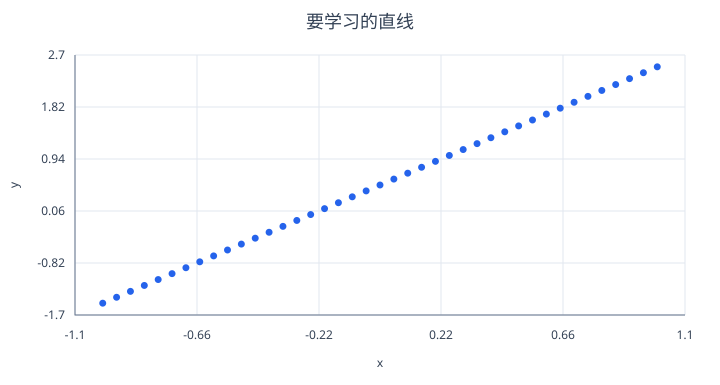

In [2]:
inputs = [[i / 20] for i in range(-20, 21)]
targets = [[2 * x + 0.5] for [x] in inputs]

visualization.Plot(title="要学习的直线", xlabel="x", ylabel="y").scatter([x for [x] in inputs], [y for [y] in targets])

## 2. 搭模型

`Linear(1, 1)` 有一个权重和一个偏置，正好表示一条直线。`MSE` 衡量预测与目标之间的平方误差。

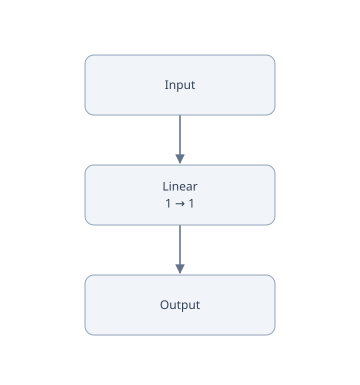

In [3]:
model = nn.Model([nn.Linear(1, 1)]).to(device)
optimizer = nn.SGD(model, learning_rate=0.1)
loss_function = nn.MSE()
data = Stream(inputs, targets, batch_size=16, device=device, progress=False)
epochs = 15

visualization.Network(model)

## 3. 训练

一轮 epoch 会遍历一次数据。每个批次都重复四件事：清梯度、算损失、反向传播、更新参数。后面的教程继续使用这个结构；打印的是这一轮最后一批的损失。

In [4]:
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/15  loss 2.710414
epoch 2/15  loss 0.925271
epoch 3/15  loss 0.465566
epoch 4/15  loss 0.582299
epoch 5/15  loss 0.283571
epoch 6/15  loss 0.163066
epoch 7/15  loss 0.074521
epoch 8/15  loss 0.071947
epoch 9/15  loss 0.030858
epoch 10/15  loss 0.025293
epoch 11/15  loss 0.008070
epoch 12/15  loss 0.010991
epoch 13/15  loss 0.002476
epoch 14/15  loss 0.003752
epoch 15/15  loss 0.004532


## 4. 看结果

`train=False` 用于预测。把预测曲线与公式画在一起，越重合说明模型学得越接近。

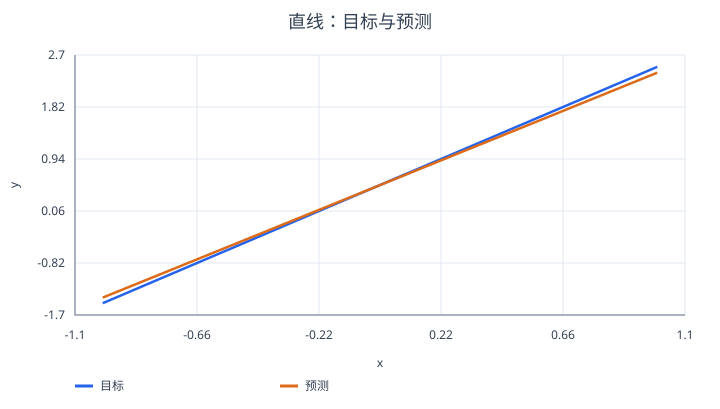

In [5]:
xs = [i / 20 for i in range(-20, 21)]
predictions = model([[x] for x in xs], train=False).tolist()

visualization.Plot(title="直线：目标与预测", xlabel="x", ylabel="y").line(xs, [2 * x + 0.5 for x in xs], label="目标").line(xs, [y for [y] in predictions], label="预测")

## 5. 换成 x²

数据和模型变了，训练流程不变。隐藏层的 ReLU 让多条线段组合出弯曲的函数；一层 Linear 单独做不到这一点。

In [6]:
inputs = [[i / 20] for i in range(-20, 21)]
targets = [[x * x] for [x] in inputs]

model = nn.Model([
    nn.Linear(1, 16),
    nn.ReLU(),
    nn.Linear(16, 1)]
).to(device)
optimizer = nn.AdamW(model, learning_rate=0.03)
loss_function = nn.MSE()
data = Stream(inputs, targets, batch_size=16, device=device, progress=False)
epochs = 30

# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/30  loss 0.073993
epoch 2/30  loss 0.060465
epoch 3/30  loss 0.036544
epoch 4/30  loss 0.014439
epoch 5/30  loss 0.028484
epoch 6/30  loss 0.021086
epoch 7/30  loss 0.002016
epoch 8/30  loss 0.004655
epoch 9/30  loss 0.003348
epoch 10/30  loss 0.003137
epoch 11/30  loss 0.003880
epoch 12/30  loss 0.010578
epoch 13/30  loss 0.000925
epoch 14/30  loss 0.002085
epoch 15/30  loss 0.001640
epoch 16/30  loss 0.000963
epoch 17/30  loss 0.003130
epoch 18/30  loss 0.000966
epoch 19/30  loss 0.001210
epoch 20/30  loss 0.001072
epoch 21/30  loss 0.001891
epoch 22/30  loss 0.001144
epoch 23/30  loss 0.000563
epoch 24/30  loss 0.001081
epoch 25/30  loss 0.000157
epoch 26/30  loss 0.001386
epoch 27/30  loss 0.000197
epoch 28/30  loss 0.000449
epoch 29/30  loss 0.000168
epoch 30/30  loss 0.000769


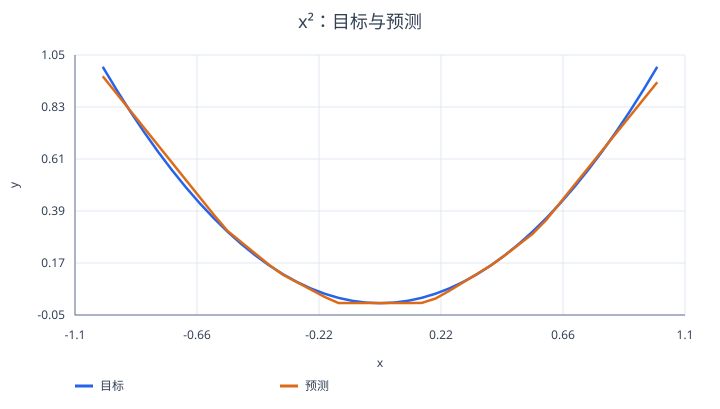

In [7]:
predictions = model([[x] for x in xs], train=False).tolist()

visualization.Plot(title="x²：目标与预测", xlabel="x", ylabel="y").line(xs, [x * x for x in xs], label="目标").line(xs, [y for [y] in predictions], label="预测")

## 6. 保存，再加载

保存文件包含结构和参数。空模型调用 `load` 就能恢复，无需再搭一遍网络；加载后再选择计算设备。

文件保存在 Notebook 的当前工作目录。文件不存在时 save 会新建；删除后也可以重新保存。

In [10]:
samples = [[-0.8], [0], [0.8]]
before = model(samples, train=False).tolist()
model.save("regression.json")
model = nn.Model().load("regression.json").to(device)
after = model(samples, train=False).tolist()

print("保存前：", before)
print("加载后：", after)
assert before == after

保存前： [[0.655552327632904], [0.030038179829716682], [0.6727021932601929]]
加载后： [[0.655552327632904], [0.030038179829716682], [0.6727021932601929]]
